# 1a — Discrétisation · Segment : Comptes joints

**Objectif** : dérouler le chapitre 4 du cours sur les variables candidates issues du notebook `0d`. Chaque
variable devient un ensemble de classes ordonnées de risque, avec leur WoE : c'est l'entrée de la régression
logistique (ch. 5).

| § | Thème | Traitement appliqué ici |
|---|-------|-------------------------|
| 4.1 | Objectifs | linéariser X→Y, robustesse aux extrêmes, interprétabilité, préparation WoE / IV |
| 4.2 | Méthodes | découpage fin en 20 quantiles (comparé à l'arbre univarié), puis fusion de type ChiMerge |
| 4.3 | WoE / IV | table par classe ; perte d'IV entre découpage fin et découpage final |
| 4.4 | Monotonie | imposée dans le sens du Spearman avec la cible, sauf exception documentée |
| 4.5 | Modalités rares, missing | fusion avec la classe de taux le plus proche ; missing isolé s'il se distingue |
| 4.6 | Stabilité | écart relatif ≥ 30 % entre classes consécutives en moyenne sur les cohortes ; volume (PSI) |
| 4.7 | Processus | découpage fin → fusion progressive → validation → export |

> **Apprentissage / test** (cours 1.5.4) : les découpages sont appris sur l'**apprentissage** seul, puis appliqués sans
> réestimation à toute la base (`appliquer_decoupages`). L'échantillon Out-of-Time sera une base fournie séparément.
>
> Ce notebook est un **rapport lisible** : les calculs sont délégués à `utils/binning.py`.
> Seuls les paramètres et les décisions figurent ici.

## 0. Imports et configuration

In [1]:
import sys, json
from pathlib import Path

# Racine du projet : ce notebook est rangé dans Segmentation_joint/
ROOT = Path.cwd().parent if Path.cwd().name == "Segmentation_joint" else Path.cwd()
sys.path.insert(0, str(ROOT))

import polars as pl
import matplotlib.pyplot as plt

from utils.binning import (
    discretiser, appliquer_decoupages, stabilite_decoupages, plot_decoupages, plot_stabilite,
)
from utils.exploration import exporter_excel
from utils.synthese import (
    afficher, constat_methodes, constat_decoupages, constat_stabilite, synthese_discretisation,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 120
pl.Config.set_tbl_rows(40)

polars.config.Config

### Paramètres

| Paramètre | Valeur | Justification |
|-----------|--------|---------------|
| `n_bins` | 20 | découpage fin « relativement granulaire » (4.7) |
| `min_part` | 1 % | effectif minimal par classe (≈ 410 dossiers en apprentissage). Un seuil de 5 % fusionnait toute modalité minoritaire : les variables d'arriérés (`NBJ_ARR_SS_*`, `ARR_GDT`), rares mais très prédictives, tombaient à une seule classe |
| `min_defauts` | 20 | WoE stable (4.5), soit 10 % des 200 défauts de l'apprentissage ; à 50, aucune variable ne dépassait 2 classes |
| `seuil_ecart` | 30 % | règle de stabilité en risque (4.6) |
| `alpha` | 10 % | ChiMerge : deux classes adjacentes non distinctes à 10 % sont fusionnées (4.2). Seuil volontairement plus large qu'au ch. 5, où chaque modalité est re-testée à 5 % (Wald) et fusionnée si besoin |
| `max_classes` | 6 | parcimonie (4.3) : au-delà, le gain d'IV est surtout mécanique |
| `SEUIL_PSI` | 0,10 | stabilité en volume : seuil usuel en deçà duquel une répartition est jugée stable (9.3) |

**Calibrage des contraintes** : trois jeux de paramètres ont été comparés (découpage appris sur l'apprentissage, sélection
du ch. 5, Gini mesuré sur le test) :

| `min_part` / `min_defauts` / `alpha` | Classes en moyenne | Variables du modèle | Gini apprentissage | Gini test |
|---|---|---|---|---|
| 5 % / 50 / 5 % (réglage initial) | 1,5 | 8 | 75,5 % | 65,5 % |
| 2 % / 30 / 5 % | 1,9 | 5 | 79,0 % | 69,8 % |
| 1 % / 20 / 5 % | 2,3 | 5 | 79,6 % | 74,2 % |
| **1 % / 20 / 10 % (retenu)** | 2,3 | 7 | 81,7 % | 74,8 % |

Ce choix utilise l'échantillon de test : la validation réellement indépendante sera l'échantillon Out-of-Time.

In [2]:
BASE       = ROOT / "data/segments/joint/base_joint_prep.parquet"
CANDIDATES = ROOT / "outputs/exploration/variables_candidates_joint.json"     # sortie du notebook 0d
SORTIE_DEC = ROOT / "outputs/binning/decoupages_joint.json"                    # découpages retenus
SORTIE_XLS = ROOT / "outputs/binning/discretisation_joint.xlsx"
SORTIE_CL  = ROOT / "data/segments/joint/base_joint_classes.parquet"           # entrée du ch. 5

TARGET   = "ddefaut_ndb"   # variable cible (0/1)
ID_COL   = "gdt"           # identifiant
DATE_COL = "datdelhis"     # date d'observation

# Règles de découpage (cours 4.2 à 4.6)
REGLES = dict(
    methode       = "quantiles",  # découpage fin : "quantiles" ou "arbre"
    n_bins        = 20,
    max_modalites = 15,           # en dessous, une numérique a une classe fine par valeur (comme en 0c / 0d)
    min_part      = 0.01,
    min_defauts   = 20,
    seuil_ecart   = 0.30,
    alpha         = 0.10,
    max_classes   = 6,
)
SEUIL_PSI = 0.10
COHORTE   = "1mo"                 # cohortes mensuelles : la base ne couvre que 4 mois (une seule année)
IV_MIN    = 0.02

## 1. Chargement

Base préparée par `0c` (manquant = modalité `"missing"` pour les qualitatives, `null` pour les quantitatives),
restreinte aux variables candidates retenues par `0d`.

In [3]:
if not BASE.exists():
    raise FileNotFoundError(f"{BASE} introuvable : exécuter d'abord les notebooks 0c et 0d.")

df = pl.read_parquet(BASE)
df_app = df.filter(pl.col("echantillon") == "apprentissage")   # les découpages sont appris ici

VARS = [v for v in json.loads(CANDIDATES.read_text(encoding="utf-8")) if v in df.columns]

print(f"{len(VARS)} variables candidates | base : {df.height} lignes, "
      f"{int(df[TARGET].sum())} défauts ({df[TARGET].mean():.2%})")
print(f"apprentissage : {df_app.height} lignes, {int(df_app[TARGET].sum())} défauts")

51 variables candidates | base : 58947 lignes, 284 défauts (0.48%)
apprentissage : 41266 lignes, 200 défauts


## 4.1 – 4.2 Objectifs et méthode de découpage

La régression logistique suppose une relation linéaire entre le logit et chaque variable. En remplaçant la
variable par des classes, on capte des effets non linéaires dans un cadre linéaire par morceaux, on absorbe les
valeurs extrêmes dans les classes de bord, et chaque classe reçoit un libellé métier.

**Méthode retenue** : découpage fin puis regroupement supervisé, qui combine trois approches du cours :

1. **quantiles** pour le découpage fin (volume garanti par classe) ;
2. **ChiMerge** pour la fusion : la paire adjacente de plus faible Chi² est fusionnée en priorité ;
3. **contraintes** de 4.4 à 4.6 (monotonie, effectif, écart de 30 %), qui priment sur l'optimum statistique.

L'arbre univarié est comparé ci-dessous sur les variables les plus discriminantes : si les deux méthodes
aboutissent à des nombres de classes et à des IV proches, le choix du découpage fin est sans conséquence.

In [4]:
VARS_COMP = VARS[:8]
regles_sans_methode = {k: v for k, v in REGLES.items() if k != "methode"}

comparaison = pl.concat([
    discretiser(df_app, VARS_COMP, TARGET, methode=m, **regles_sans_methode)[2]
    .select("variable", pl.lit(m).alias("methode"), "n_classes", "iv")
    for m in ("quantiles", "arbre")
]).pivot(on="methode", index="variable", values=["n_classes", "iv"])
comparaison

variable,n_classes_quantiles,n_classes_arbre,iv_quantiles,iv_arbre
str,u32,u32,f64,f64
"""MINSOLDE_PAR""",4,3,1.889728,1.684475
"""CRTAD_AG_NBJDE_BA""",5,4,1.540521,1.560451
"""solde_crediteur""",3,3,1.42327,1.393366
"""CRTAD_IND_0015""",4,4,1.290643,1.344133
"""ENCOURS_PAR""",2,2,1.093571,1.209101
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…",2,2,1.068362,1.068362
"""ARR_GDT""",2,2,0.966741,0.881394
"""NBJDE_RATIO_A_vs_A1""",4,3,0.773544,0.785888


In [5]:
afficher(constat_methodes(comparaison))

- Sur 8 variables : IV final à ±10% près pour **6** ; même nombre de classes pour **5**.
- Écart d'IV médian (arbre − quantiles, en relatif) : **0,6%**.
- Variables où l'arbre fait nettement mieux : `ENCOURS_PAR`.

**Lecture** : sur les 8 variables les plus discriminantes, les deux méthodes donnent des IV finaux proches (écart
médian de 0,6 %, à ±10 % près pour 6 variables sur 8) et des nombres de classes voisins. Le choix du découpage fin pèse
donc peu : ce sont les contraintes de fusion (effectif, 30 %, monotonie) qui déterminent le résultat. On retient les
**quantiles**, qui garantissent un effectif par classe fine et ne dépendent pas de la cible avant la phase de fusion.

## 4.3 – 4.4 Découpage final, WoE et monotonie

Fusion progressive, une paire de classes adjacentes à la fois, par ordre de priorité :

1. classe trop petite (< 5 % des dossiers ou < 50 défauts) → fusion avec le voisin de taux le plus proche ;
2. rupture de monotonie → fusion ;
3. écart relatif de taux de défaut < 30 %, ou Chi² non significatif → fusion ;
4. plus de 6 classes → fusion de la paire la moins distincte.

**Monotonie** : imposée par défaut dans le sens du Spearman entre la variable et la cible. Une variable signalée
non monotone en 3.5 n'en est exemptée (`SENS[var] = 0`) que si sa forme a un sens métier connu et stable (4.4).
Ses classes sont alors regroupées par niveau de risque : les deux extrémités d'une relation en U peuvent former
une seule classe.

**WoE** = ln(%bons / %mauvais) : positif pour une classe moins risquée que la moyenne. La colonne `perte_iv`
mesure l'IV abandonné entre le découpage fin et le découpage final : l'IV croît mécaniquement avec le nombre de
classes (4.3), une perte modérée est donc le prix normal de la parcimonie.

Les classes sont numérotées de 1 (la moins risquée) à N (la plus risquée), missing compris (4.6).

In [6]:
# Sens de monotonie imposé : par défaut, signe du Spearman avec la cible.
# 0 = relation non monotone acceptée (justification métier obligatoire, cf. 0d section 3.5 et cours 4.4).
SENS = {
    # "VARIABLE": 0,
}

decoupages, tables, bilan = discretiser(df_app, VARS, TARGET, sens=SENS, **REGLES)

print(f"{bilan.height} variables découpées | classes : {bilan['n_classes'].min()} à {bilan['n_classes'].max()} "
      f"| perte d'IV médiane : {bilan['perte_iv'].median():.0%}")
bilan

51 variables découpées | classes : 1 à 5 | perte d'IV médiane : 21%


variable,nature,sens,n_classes_fin,n_classes,iv_fin,iv,perte_iv,part_min,defauts_min,ecart_relatif_min,missing_isole
str,str,i64,i64,u32,f64,f64,f64,f64,f64,f64,bool
"""MINSOLDE_PAR""","""numerique""",-1,20,4,2.023938,1.889728,0.066311,0.099767,22.0,1.028212,false
"""CRTAD_AG_NBJDE_BA""","""numerique""",1,12,5,1.576592,1.540521,0.022879,0.049581,21.0,0.419552,false
"""solde_crediteur""","""numerique""",-1,20,3,1.706519,1.42327,0.165981,0.099985,42.0,1.522587,false
"""CRTAD_IND_0015""","""numerique""",1,7,4,1.320645,1.290643,0.022717,0.049653,33.0,1.039221,false
"""ENCOURS_PAR""","""numerique""",-1,17,2,1.296988,1.093571,0.156838,0.300296,41.0,8.036054,false
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…","""numerique""",1,13,2,1.172381,1.068362,0.088725,0.30015,42.0,7.771501,true
"""ARR_GDT""","""numerique""",1,2,2,0.966741,0.966741,0.0,0.032787,73.0,15.95648,false
"""NBJDE_RATIO_A_vs_A1""","""numerique""",1,18,4,0.9769,0.773544,0.208165,0.105971,27.0,0.503097,true
"""horsbilan""","""numerique""",-1,12,2,0.643286,0.610749,0.050578,0.451146,37.0,4.359512,false


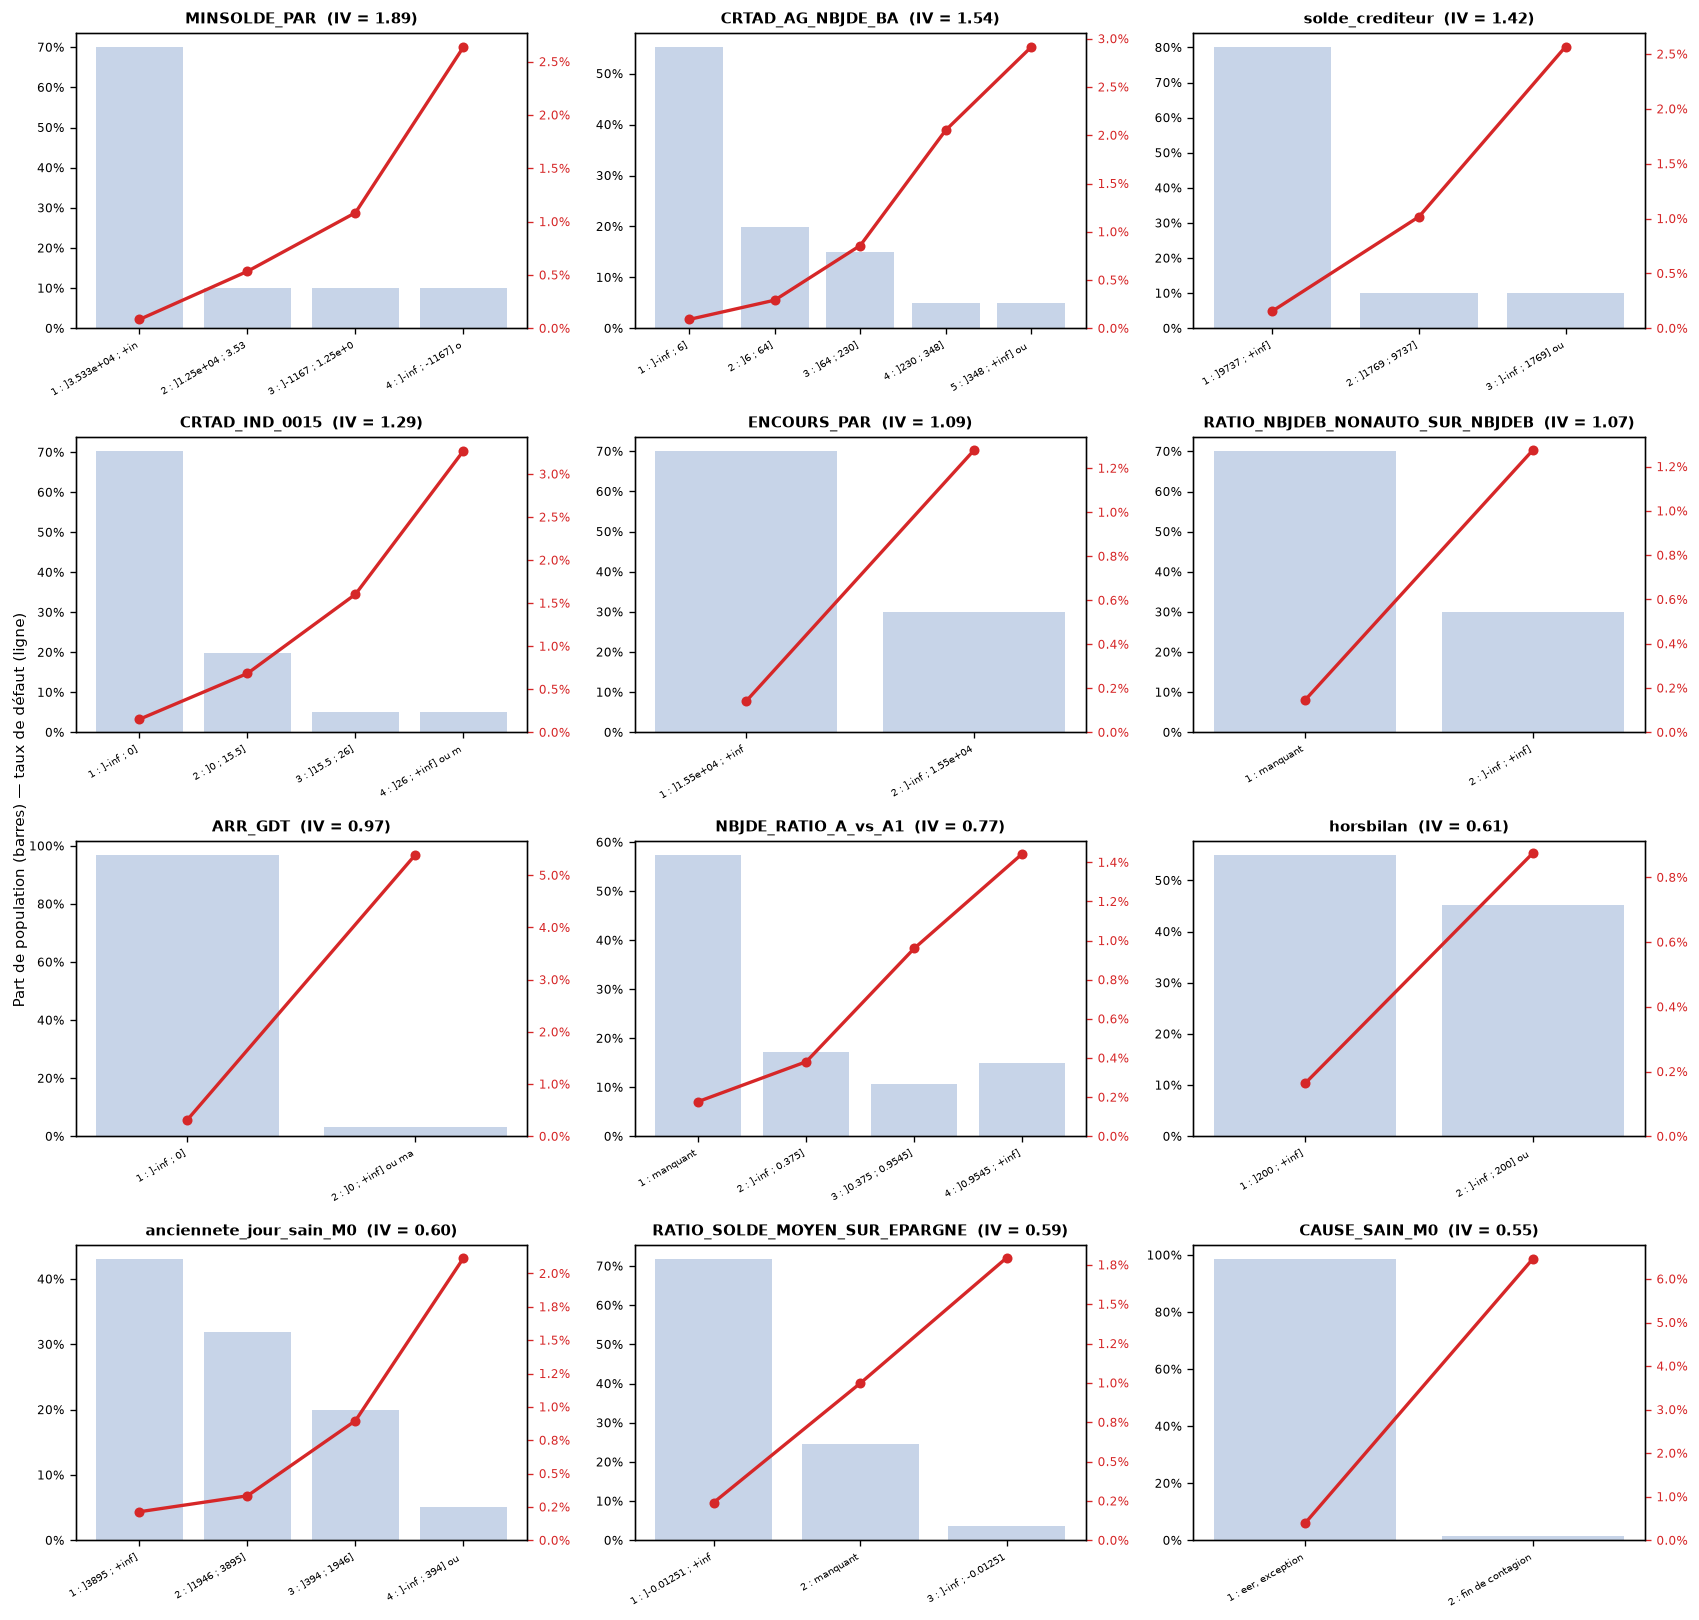

In [7]:
VARS_GRAPHE = bilan["variable"].head(12).to_list()

fig = plot_decoupages(tables, VARS_GRAPHE)
plt.show()

In [8]:
# Table WOE / IV détaillée des variables affichées
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    display(tables.filter(pl.col("variable").is_in(VARS_GRAPHE)))

variable,classe,libelle,n,n_defaut,taux_defaut,part_population,woe,iv,ecart_relatif
str,i32,str,u32,f64,f64,f64,f64,f64,f64
"""MINSOLDE_PAR""",1,"""]3.533e+04 ; +inf]""",28864,24.0,0.000831,0.699462,1.748729,1.014426,null
"""MINSOLDE_PAR""",2,"""]1.25e+04 ; 3.533e+04]""",4117,22.0,0.005344,0.099767,-0.118005,0.001474,5.426686
"""MINSOLDE_PAR""",3,"""]-1167 ; 1.25e+04]""",4152,45.0,0.010838,0.100616,-0.819276,0.103976,1.028212
"""MINSOLDE_PAR""",4,"""]-inf ; -1167] ou manquant""",4133,109.0,0.026373,0.100155,-1.717902,0.769852,1.433358
"""solde_crediteur""",1,"""]9737 ; +inf]""",33012,52.0,0.001575,0.799981,1.120118,0.605723,null
"""solde_crediteur""",2,"""]1769 ; 9737]""",4126,42.0,0.010179,0.099985,-0.756683,0.085134,5.462321
"""solde_crediteur""",3,"""]-inf ; 1769] ou manquant""",4128,106.0,0.025678,0.100034,-1.69062,0.732412,1.522587
"""CRTAD_AG_NBJDE_BA""",1,"""]-inf ; 6]""",22756,21.0,0.000923,0.551447,1.641496,0.732755,null
"""CRTAD_AG_NBJDE_BA""",2,"""]6 ; 64]""",8227,24.0,0.002917,0.199365,0.491509,0.038125,2.161159


In [9]:
afficher(constat_decoupages(bilan))

- **51** variables découpées, **2,3** classes en moyenne (de 1 à 5).
- Perte d'IV médiane entre découpage fin et final : **20,9%**. Plus fortes pertes : `CRTAV_IND_0165` (100,0%), `nb_CB_diff` (100,0%), `nb_DAV` (100,0%).
- Variables numériques sans monotonie imposée (sens = 0) : aucune.
- Missing gardé comme classe à part : **9** variables (`RATIO_NBJDEB_NONAUTO_SUR_NBJDEB`, `NBJDE_RATIO_A_vs_A1`, `RATIO_SOLDE_MOYEN_SUR_EPARGNE`, `NBJ_ARR_SS_max_Mm13_Mm18`, `RATIO_LITIGES_vs_AVOIRS`, `RATIO_MOUV_AFF_SUR_EPARGNE`, `NBJ_ARR_SS_max_Mm19_Mm24`, `NBJ_ARR_SS_max_Mm37_Mm48` … (+1 autres)).

**Lecture des découpages des variables du modèle final (ch. 5)** :

| Variable | Classes (1 = la moins risquée) | Lecture métier |
|----------|--------------------------------|----------------|
| `MINSOLDE_PAR` | > 35,3 k€ · 12,5 – 35,3 k€ · −1,2 – 12,5 k€ · ≤ −1,2 k€ ou manquant | plus le solde minimum est bas, plus le risque monte ; un solde minimum débiteur de plus de 1 200 € est le cas le plus risqué |
| `CRTAD_AG_NBJDE_BA` | ≤ 6 j · 6 – 64 · 64 – 230 · 230 – 348 · > 348 j ou manquant | nombre de jours débiteurs : un compte à découvert presque toute l'année est le plus risqué |
| `ENCOURS_PAR` | > 15,5 k€ · ≤ 15,5 k€ ou manquant | un faible encours détenu signale une relation moins installée |
| `CAUSE_SAIN_M0` | « eer, exception » · « fin de contagion, retour en sain, missing » | un dossier revenu récemment au sain (sortie de défaut ou de contagion) reste nettement plus risqué |
| `SOLDE_RATIO_T_vs_HIST` | > 0,37 · ≤ 0,37 ou manquant | solde actuel tombé sous 37 % de son niveau historique : dégradation récente |
| `ANCIENNETE_modif` | > 168 mois · ≤ 168 mois ou manquant | relation de moins de 14 ans plus risquée (seuil proche de la première coupure de l'arbre du notebook 0, 13,5 ans) |
| `NBECR_EVOLUTION_A_vs_A1` | > −29 % · −43 % à −29 % ou manquant · ≤ −43 % | chute du nombre d'écritures sur un an : le compte est moins utilisé |
| `NBJ_ARR_SS_max_Mm1_Mm3` | 0 ou manquant · > 0 | au moins un jour d'arriéré sur les 3 derniers mois |

Les bornes ont toutes une lecture métier directe. **À vérifier par toi** : le regroupement de la modalité `missing` avec
« retour en sain » pour `CAUSE_SAIN_M0` (statistiquement proche, mais à confirmer avec le dictionnaire).

- Exemptions de monotonie : aucune (cf. 0d, § 3.5).
- Pertes d'IV : médiane de 21 %. Les pertes de 100 % (`CRTAV_IND_0165`, `nb_CB_diff`, `nb_DAV`…) concernent des variables
  réduites à une seule classe par les contraintes : leur signal ne résiste pas aux règles d'effectif et des 30 %.

## 4.5 Modalités rares et modalité missing

Le missing reçoit son propre WoE. Il n'est fusionné, avec la classe de taux de défaut le plus proche, que s'il est
trop petit ou s'il ne s'en distingue pas statistiquement (écart < 30 % ou Chi² non significatif). Sinon il reste
une classe isolée, au rang de son risque (signal MNAR). Les modalités qualitatives rares rejoignent la modalité de
WoE le plus proche.

Une valeur jamais observée en apprentissage (modalité nouvelle, manquant absent de l'apprentissage) est affectée
à la classe la plus risquée : choix prudent, qui garantit que toute valeur reçoit une classe.

In [10]:
missing_par_variable = (
    tables.filter(pl.col("libelle").str.contains("manquant|missing"))
    .join(bilan.select("variable", "missing_isole"), on="variable")
    .select("variable", "missing_isole", "classe", "libelle", "n", "taux_defaut", "woe")
)
print(f"{bilan.filter(pl.col('missing_isole')).height} variables où le manquant forme une classe à part")
missing_par_variable.sort("missing_isole", "variable", descending=[True, False])

9 variables où le manquant forme une classe à part


variable,missing_isole,classe,libelle,n,taux_defaut,woe
str,bool,i32,str,u32,f64,f64
"""NBJDE_RATIO_A_vs_A1""",true,1,"""manquant""",23645,0.001776,0.997512
"""NBJ_ARR_SS_max_Mm13_Mm18""",true,2,"""manquant""",1704,0.012324,-0.961556
"""NBJ_ARR_SS_max_Mm19_Mm24""",true,2,"""manquant""",2665,0.010507,-0.794451
"""NBJ_ARR_SS_max_Mm25_Mm36""",true,2,"""manquant""",3683,0.00896,-0.63106
"""NBJ_ARR_SS_max_Mm37_Mm48""",true,2,"""manquant""",5550,0.009189,-0.651303
"""RATIO_LITIGES_vs_AVOIRS""",true,2,"""manquant""",8798,0.010912,-0.820311
"""RATIO_MOUV_AFF_SUR_EPARGNE""",true,2,"""manquant""",8798,0.010912,-0.820311
"""RATIO_NBJDEB_NONAUTO_SUR_NBJDE…",true,1,"""manquant""",28880,0.001454,1.197829
"""RATIO_SOLDE_MOYEN_SUR_EPARGNE""",true,2,"""manquant""",10121,0.009979,-0.729804


## 4.6 Stabilité dans le temps

Deux règles de conception, mesurées sur l'apprentissage par **cohorte mensuelle** (la base ne couvre que janvier à avril 2021 :
une cohorte annuelle n'en donnerait qu'une, et la stabilité ne serait pas mesurable) :

- **en risque** : l'écart relatif de taux de défaut entre classes consécutives, en moyenne sur les cohortes,
  doit atteindre 30 % pour chaque paire ; `part_groupes_ordonnes` donne la part des cohortes où l'ordre des
  classes est intégralement respecté ;
- **en volume** : la répartition des classes de chaque cohorte ne doit pas s'écarter de la répartition
  d'ensemble (PSI ≤ 0,10 ; le PSI est formalisé en 9.3).

In [11]:
df_cl = appliquer_decoupages(df_app, decoupages).with_columns(
    cohorte=pl.col(DATE_COL).dt.truncate(COHORTE).dt.to_string("%Y-%m")
)
display(df_cl.group_by("cohorte").agg(n=pl.len(), n_defaut=pl.col(TARGET).sum()).sort("cohorte"))

detail_stab, stab = stabilite_decoupages(df_cl, VARS, TARGET, "cohorte",
                                         seuil_ecart=REGLES["seuil_ecart"], seuil_psi=SEUIL_PSI)
instables = stab.filter(~pl.col("stable_risque") | ~pl.col("stable_volume"))
print(f"{instables.height} variables instables sur {stab.height}")
instables

cohorte,n,n_defaut
str,u32,f64
"""2021-01""",10240,56.0
"""2021-02""",10353,47.0
"""2021-03""",10358,44.0
"""2021-04""",10315,53.0


1 variables instables sur 51


variable,ecart_moyen_min,part_groupes_ordonnes,psi_max,stable_risque,stable_volume
str,f64,f64,f64,bool,bool
"""anciennete_jour_sain_M0""",0.826298,0.75,0.368708,true,false


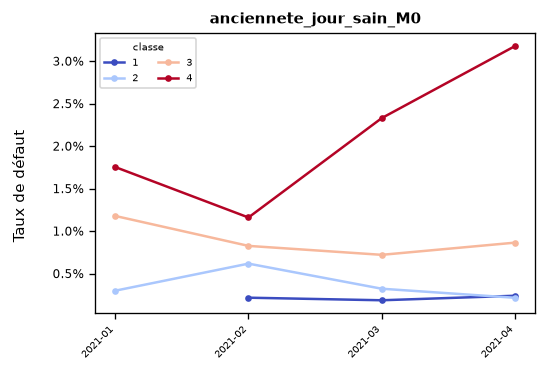

In [12]:
fig = plot_stabilite(detail_stab, (instables["variable"].to_list() or VARS)[:9])
plt.show()

In [13]:
afficher(constat_stabilite(stab, n_cohortes=df_cl["cohorte"].n_unique()))

- Mesurée sur **4** cohortes.
- Instables en risque (écart moyen < 30 % pour au moins une paire de classes) : **0** — aucune.
- Instables en volume (PSI > seuil) : **1** — `anciennete_jour_sain_M0`.
- Part médiane des cohortes où l'ordre des classes est intégralement respecté : **100%**.

**Lecture** : avec environ 50 défauts par mois en apprentissage, les taux par classe et par mois restent bruités ; pourtant
aucune variable n'est instable en risque et l'ordre des classes est respecté dans 100 % des mois (médiane).

Une seule variable est instable **en volume** : `anciennete_jour_sain_M0` (PSI max 0,37). C'est un compteur de jours depuis le
retour au sain : il augmente mécaniquement d'un mois sur l'autre, et la population glisse d'une classe à la suivante. Ce
glissement est structurel et se reproduirait sur l'OOT : la variable est **écartée** (statut « à revoir », non transmise).
L'information qu'elle porte (passé de défaut récent) reste captée par `CAUSE_SAIN_M0`.

## 4.7 Validation finale

Une variable est **retenue** si son découpage final compte au moins 2 classes, garde un IV ≥ 0,02, et est stable
en risque et en volume dans le temps. Une variable **à revoir** n'est pas écartée d'office :
on resserre son découpage (`max_classes` plus faible, exemption de monotonie justifiée) puis on relance.

In [14]:
fiche = (
    bilan.select("variable", "nature", "sens", "n_classes", "iv_fin", "iv", "perte_iv", "missing_isole")
    .join(stab.select("variable", "ecart_moyen_min", "part_groupes_ordonnes", "psi_max",
                      "stable_risque", "stable_volume"), on="variable")
    .with_columns(
        statut=pl.when(pl.col("n_classes") < 2).then(pl.lit("écartée : une seule classe après regroupement"))
        .when(pl.col("iv") < IV_MIN).then(pl.lit("écartée : IV < 0,02 après regroupement"))
        .when(~pl.col("stable_risque")).then(pl.lit("à revoir : instable en risque"))
        .when(~pl.col("stable_volume")).then(pl.lit("à revoir : instable en volume"))
        .otherwise(pl.lit("retenue"))
    )
    .sort("iv", descending=True)
)
fiche.group_by("statut").len().sort("len", descending=True)

statut,len
str,u32
"""retenue""",40
"""écartée : une seule classe apr…",10
"""à revoir : instable en volume""",1


In [15]:
with pl.Config(tbl_rows=-1, fmt_str_lengths=60):
    display(fiche.filter(pl.col("statut") != "retenue"))

variable,nature,sens,n_classes,iv_fin,iv,perte_iv,missing_isole,ecart_moyen_min,part_groupes_ordonnes,psi_max,stable_risque,stable_volume,statut
str,str,i64,u32,f64,f64,f64,bool,f64,f64,f64,bool,bool,str
"""anciennete_jour_sain_M0""","""numerique""",-1,4,0.62573,0.595062,0.049012,false,0.826298,0.75,0.368708,true,false,"""à revoir : instable en volume"""
"""CRTAD_IND_0205""","""numerique""",-1,1,0.08454,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""CRTAV_IND_0165""","""numerique""",-1,1,0.621802,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""RATIO3_PRO""","""numerique""",-1,1,0.036261,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""compte_inactif""","""qualitative""",1,1,0.054767,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""nb_CB_diff""","""numerique""",-1,1,0.208133,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""nb_DAV""","""numerique""",-1,1,0.132157,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""nb_credit_immo__autre_garantie""","""numerique""",-1,1,0.020751,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""
"""nb_credit_immo__hypotheque""","""numerique""",1,1,0.065732,0.0,1.0,false,null,1.0,0.0,true,true,"""écartée : une seule classe après regroupement"""


### Export

- les découpages retenus (bornes, regroupements, classe du missing), réutilisables tels quels sur tout nouvel échantillon ;
- les tables WoE / IV et de stabilité, pour le dossier de validation ;
- la base en classes, entrée du chapitre 5.

In [16]:
VARS_RETENUES = fiche.filter(pl.col("statut") == "retenue")["variable"].to_list()

SORTIE_DEC.parent.mkdir(parents=True, exist_ok=True)
SORTIE_DEC.write_text(json.dumps({v: decoupages[v] for v in VARS_RETENUES}, ensure_ascii=False, indent=1),
                      encoding="utf-8")
exporter_excel({"fiche": fiche, "tables_woe": tables, "stabilite": stab, "detail_stabilite": detail_stab},
               SORTIE_XLS)

appliquer_decoupages(df, {v: decoupages[v] for v in VARS_RETENUES}).write_parquet(SORTIE_CL)
print(f"{len(VARS_RETENUES)} variables retenues")
print(f"Découpages : {SORTIE_DEC}\nTables     : {SORTIE_XLS}\nBase       : {SORTIE_CL}")

40 variables retenues
Découpages : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\binning\decoupages_joint.json
Tables     : C:\Users\anisz\OneDrive\Desktop\Scorign\outputs\binning\discretisation_joint.xlsx
Base       : C:\Users\anisz\OneDrive\Desktop\Scorign\data\segments\joint\base_joint_classes.parquet


## Synthèse des décisions

Le tableau ci-dessous est rempli à partir des résultats. Décisions complémentaires :

- **4.4** : aucune exemption de monotonie (choix par défaut du cours, aucune relation en U jugée stable) ;
- **4.6** : `anciennete_jour_sain_M0` écartée (dérive structurelle d'un compteur de jours) ;
- **paramètres** : 1 % / 20 défauts / ChiMerge à 10 %, choisis pour ne pas écraser les variables d'arriérés (cf. Paramètres).

> **Prochaine étape** : régression logistique sur les classes (ch. 5), modalité 1 = référence.

In [17]:
afficher(synthese_discretisation(comparaison, bilan, fiche))

| § | Constat | Décision |
|---|---|---|
| 4.2 Méthode | écart d'IV médian arbre / quantiles : 0,6% | quantiles fins + fusion ChiMerge sous contraintes |
| 4.3 WoE / IV | perte d'IV médiane de 20,9% pour 2,3 classes en moyenne | perte acceptée au titre de la parcimonie |
| 4.4 Monotonie | 0 exemptions : aucune | monotonie imposée partout |
| 4.5 Missing | isolé pour 9 variables sur 51 | fusionné avec la classe de risque la plus proche ailleurs |
| 4.6 Stabilité | 1 variables à revoir | variables à revoir non transmises au ch. 5 |
| 4.7 Bilan | 40 retenues, 1 à revoir, 10 écartées | variables retenues transmises au ch. 5 |